# M02-3 | 手動重做 convert_pt2e：observer → quantize／dequantize

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m02_observer_fakequant/03_observer_to_qdq.ipynb)

M02-2 手做了 `prepare_pt2e`。這本 notebook 手做 `convert_pt2e`，最後和它的結果逐項比對。

先看 `convert_pt2e` 依序做了什麼（torchao 0.18 `quantize_pt2e.py`）：

| 順序 | 步驟 | 做什麼 | 本 notebook |
|---|---|---|---|
| 1 | observer → q/dq | 每個 observer 換成一對 quantize／dequantize，scale 與 zero point 寫進圖裡 | B 段 |
| 2 | `_fold_conv_bn_qat` | 折掉 QAT 訓練時留著的 conv + bn 子圖 | 略過（PTQ 的 BN 在 prepare 就折掉了，M04） |
| 3 | `DuplicateDQPass` | 一個 dequantize 有多個使用者時，替每個使用者複製一份 | C 段 |
| 4 | `PortNodeMetaForQDQ` | 把標註等 metadata 搬到 q/dq node 上 | 略過（不影響圖的結構與數值） |
| 5 | `constant_fold` | weight 的 quantize 輸入是常數，預先算好，只存 int8 | D 段 |

開始之前，**A** 段先確認 quantize／dequantize 這兩個 op 的數學。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m02_observer_fakequant")

In [1]:
import copy

import torch
from torch.fx import Graph
from torch.fx.passes.infra.pass_manager import PassManager
from torch.fx.passes.utils.matcher_utils import SubgraphMatcher

from common.data import calibration_batches
from common.graph_utils import diff_ops, observer_nodes, op_counts
from common.models import example_inputs, get_model
from common.pt2e import DuplicateDQPass, convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

QD = torch.ops.quantized_decomposed  # convert_pt2e 產生的 q/dq op 都在這個 namespace

## A. quantize／dequantize 的數學

兩個 op 就是 M01 的公式：$q = \text{clamp}(\text{round}(x/s) + z,\ q_{\min}, q_{\max})$，$\hat{x} = (q - z)\cdot s$。
選一個偏小的 scale，讓部分元素超出範圍、被 clamp：

In [2]:
x = torch.randn(8) * 2
scale, zp, qmin, qmax = 0.02, 3, -128, 127

q_op = QD.quantize_per_tensor(x, scale, zp, qmin, qmax, torch.int8)
dq_op = QD.dequantize_per_tensor(q_op, scale, zp, qmin, qmax, torch.int8)
q_hand = (torch.round(x / scale) + zp).clamp(qmin, qmax).to(torch.int8)
dq_hand = (q_hand.to(torch.float32) - zp) * scale
clamped = ((torch.round(x / scale) + zp < qmin) | (torch.round(x / scale) + zp > qmax))

table([["x", *[f"{v:.3f}" for v in x.tolist()]],
       ["q（op）", *q_op.tolist()],
       ["q（手寫）", *q_hand.tolist()],
       ["dq（op）", *[f"{v:.3f}" for v in dq_op.tolist()]],
       ["被 clamp", *["✱" if c else "" for c in clamped.tolist()]]])

x,3.082,-0.587,-4.358,1.137,-2.169,-2.797,0.807,1.676
q（op）,127,-26,-128,60,-105,-128,43,87
q（手寫）,127,-26,-128,60,-105,-128,43,87
dq（op）,2.480,-0.580,-2.620,1.140,-2.160,-2.620,0.800,1.680
被 clamp,✱,,✱,,,✱,,


In [3]:
assert torch.equal(q_op, q_hand) and torch.equal(dq_op, dq_hand) and clamped.any()

op 與手寫公式逐位元相同。被 clamp 的元素還原後停在範圍邊界（$(q_{\max} - z)\cdot s$ 或 $(q_{\min} - z)\cdot s$），這就是 clipping 誤差。

## 準備：一張校準好、還沒 convert 的圖

`TinyConvNet`（conv-bn-relu、residual block、linear），用 XNNPACKQuantizer（per-channel weight）prepare 並校準。
`official` 是 `convert_pt2e` 的結果，後面每一步都和它比。

In [4]:
model = get_model("tiny").eval()
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(export_module(model, example_inputs(8)), quantizer)
with torch.no_grad():
    for batch in calibration_batches(n=128, batch_size=16):
        prepared(*batch)

official = convert_pt2e(copy.deepcopy(prepared))  # convert_pt2e 會原地修改，對複本呼叫
x_test = torch.randn(8, 3, 16, 16)


def max_diff(a, b):
    with torch.no_grad():
        return float((a(x_test) - b(x_test)).abs().max())


print(f"prepared 圖上的 observer 數量 = {len(observer_nodes(prepared))}")

prepared 圖上的 observer 數量 = 16


## B. 步驟 1：observer → q/dq

對每個 observer：用 `calculate_qparams()` 取出 scale、zero point，在它前面插 quantize、dequantize，讓下游改吃 dequantize，再刪掉 observer。
改圖的動作就是 M00-4 的 Step 4～5（用 call_function 取代 call_module、把常數放進圖裡）。scale 與 zero point 放的位置依量化方式而定：

- **per-tensor**：scale、zero point 是 Python 數字，直接寫在 node 的參數裡。
- **per-channel**：scale、zero point 是 tensor，先註冊成 buffer，再用 `get_attr` node 讀出來。

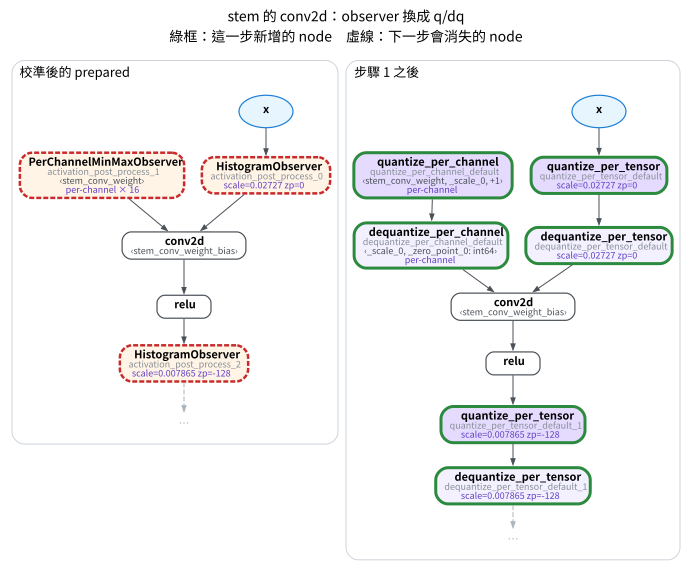

In [5]:
def replace_observers_with_qdq(gm):
    """把圖上每個 observer（call_module）換成 quantize → dequantize 兩個 call_function。"""
    graph = gm.graph
    for k, (node, obs) in enumerate(observer_nodes(gm)):
        scale, zp = obs.calculate_qparams()
        qmin, qmax, dtype = obs.quant_min, obs.quant_max, obs.dtype
        src = node.args[0]
        with graph.inserting_before(node):
            if scale.numel() > 1:  # per-channel：tensor 註冊成 buffer，用 get_attr 取
                gm.register_buffer(f"_scale_{k}", scale.detach().clone())
                gm.register_buffer(f"_zero_point_{k}", zp.detach().clone())
                s_node, z_node = graph.get_attr(f"_scale_{k}"), graph.get_attr(f"_zero_point_{k}")
                axis = int(obs.ch_axis)
                q = graph.call_function(QD.quantize_per_channel.default, (src, s_node, z_node, axis, qmin, qmax, dtype))
                dq = graph.call_function(QD.dequantize_per_channel.default, (q, s_node, z_node, axis, qmin, qmax, dtype))
            else:                  # per-tensor：Python 數字直接寫在參數裡
                s, z = float(scale), int(zp)
                q = graph.call_function(QD.quantize_per_tensor.default, (src, s, z, qmin, qmax, dtype))
                dq = graph.call_function(QD.dequantize_per_tensor.default, (q, s, z, qmin, qmax, dtype))
        node.replace_all_uses_with(dq)
        graph.erase_node(node)
        gm.delete_submodule(node.target)  # observer 模組用完就丟
    graph.lint()
    gm.recompile()
    return gm


manual = replace_observers_with_qdq(copy.deepcopy(prepared))
draw_stages([(prepared, "校準後的 prepared"), (manual, "步驟 1 之後")], focus=["conv2d"], hops=2,
            title="stem 的 conv2d：observer 換成 q/dq")

左邊的三個 observer（虛線，下一步消失）在右邊各變成一對 q/dq（綠框）。
weight 那對是 per-channel，參數裡的 `_scale_0` 就是剛註冊的 buffer；activation 那對是 per-tensor，scale 直接寫在參數裡。

輸出和 `convert_pt2e` 比：

In [6]:
print(f"步驟 1 之後，與 convert_pt2e 的輸出最大差 = {max_diff(official, manual):.3e}")
assert max_diff(official, manual) == 0

步驟 1 之後，與 convert_pt2e 的輸出最大差 = 0.000e+00


數值已經完全一樣。但圖的 op 組成還有兩處不同（`official` = `convert_pt2e`，`manual` = 只做了步驟 1）：

In [7]:
table(diff_ops(official, manual, "official", "manual", tablefmt="html"))

op,official,manual,delta
dequantize_per_tensor,12,11,-1
quantize_per_channel,0,5,5
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
dequantize_per_channel,5,5,0
flatten,1,1,0
linear,1,1,0
max_pool2d,2,2,0
quantize_per_tensor,11,11,0


In [8]:
co, cm = op_counts(official), op_counts(manual)
assert co["quantize_per_channel"] == 0 and cm["quantize_per_channel"] == 5
assert co["dequantize_per_tensor"] == cm["dequantize_per_tensor"] + 1

1. `quantize_per_channel`：`official` 沒有，因為 weight 的 quantize 被預先算掉了（步驟 5，D 段）。
2. `dequantize_per_tensor`：`official` 多一個（步驟 3，C 段）。

## C. 步驟 3：`DuplicateDQPass`

找出目前被多個使用者共用的 dequantize：

In [9]:
def shared_dqs(gm):
    return [n.name for n in gm.graph.nodes
            if n.op == "call_function" and n.target == QD.dequantize_per_tensor.default and len(n.users) > 1]


before = copy.deepcopy(manual)
shared = shared_dqs(manual)
manual = PassManager([DuplicateDQPass()])(manual).graph_module
print(f"套用前，被多個使用者共用的 dequantize：{shared}")
print(f"套用後：{shared_dqs(manual)}")
assert len(shared) == 1 and shared_dqs(manual) == []

套用前，被多個使用者共用的 dequantize：['dequantize_per_tensor_default_2']
套用後：[]


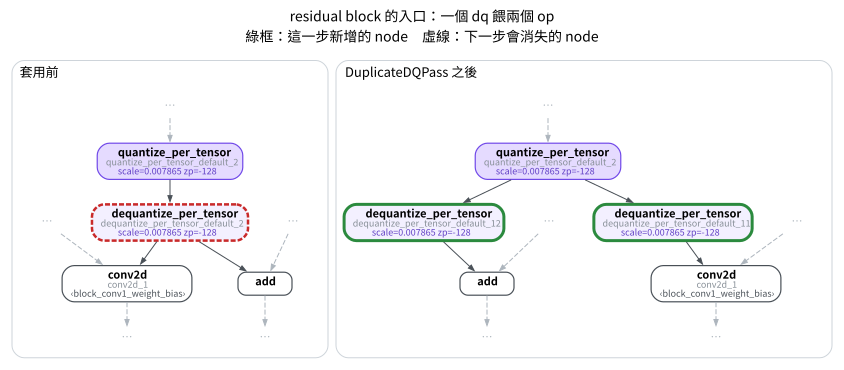

In [10]:
draw_stages([(before, "套用前"), (manual, "DuplicateDQPass 之後")], focus=shared,
            title="residual block 的入口：一個 dq 餵兩個 op")

這是 residual block 的入口：同一個 dequantize 同時餵給 `conv2d_1` 和 `add`。套用之後，兩個使用者各有一份自己的 dequantize。

共用一個 dq 會有什麼問題？M01 概覽提過，後端要讓 int8 真的變快，是在 Q/DQ 圖上找「dq → op → q」這個 pattern，
把整段換成一個 int8 kernel。這個「把 Q/DQ 圖換成後端 kernel」的動作叫 **lowering**（M07 起實際做）。

換掉的時候，pattern 裡的 dq 會跟著消失。但上圖左邊那個 dq 還要餵給 `add`：
如果把「dq → conv2d_1」換成一個 int8 conv，`add` 就少了輸入。
所以比對 pattern 時，只要 pattern 內部的 node 還有外面的使用者，這一段就**不能**算配對成功。
torch.fx 的 `SubgraphMatcher` 就是這樣規定的（原始碼的 `_is_contained`：配到的 node 不能有 pattern 以外的使用者，pattern 的輸入與輸出除外）。

實際用 `SubgraphMatcher` 在兩張圖上找「dq → conv2d」（只比對 pattern 的前半段，參數的數值不比對），看哪些 conv 配得到：

In [11]:
def dq_conv_matcher(gm):
    """「dequantize → conv2d」的 pattern；參數個數照圖上的 conv2d，數值不比對（ignore_literals）。"""
    conv = next(n for n in gm.graph.nodes if n.target == torch.ops.aten.conv2d.default)
    dq = conv.args[0]
    pattern = Graph()
    xq, w, b = pattern.placeholder("xq"), pattern.placeholder("w"), pattern.placeholder("b")
    x = pattern.call_function(dq.target, (xq, *dq.args[1:]))
    pattern.output(pattern.call_function(conv.target, (x, w, b, *conv.args[3:])))
    return SubgraphMatcher(pattern, ignore_literals=True)


matcher = dq_conv_matcher(manual)


def matched_convs(gm):
    return sorted(n.name for m in matcher.match(gm.graph) for n in m.nodes_map.values()
                  if n.target == torch.ops.aten.conv2d.default)


table([["套用前（dq 共用）", ", ".join(matched_convs(before))],
       ["DuplicateDQPass 之後", ", ".join(matched_convs(manual))]],
      ["圖", "配得到「dq → conv2d」的 conv"])

圖,配得到「dq → conv2d」的 conv
套用前（dq 共用）,"conv2d, conv2d_2, conv2d_3"
DuplicateDQPass 之後,"conv2d, conv2d_1, conv2d_2, conv2d_3"


In [12]:
assert "conv2d_1" not in matched_convs(before) and "conv2d_1" in matched_convs(manual)

套用前，`conv2d_1` 配不到：它前面的 dq 還要餵 `add`。套用之後，`conv2d_1` 和 `add` 各有自己的 dq，
「dq → conv2d_1」自成一段，後端可以把它換成 int8 conv，`add` 用自己那份 dq，不受影響。
這就是 `DuplicateDQPass` 的用途，它的 docstring 也這樣寫：共用一個 dequantize 的使用者無法各自被標註與 lowering。

複製只是多一個參數相同的 node，數值完全等價：

In [13]:
print(f"套用後與 convert_pt2e 的輸出最大差 = {max_diff(official, manual):.3e}")
assert max_diff(official, manual) == 0

套用後與 convert_pt2e 的輸出最大差 = 0.000e+00


## D. 步驟 5：constant folding

weight 的 quantize 輸入是常數（`get_attr` 讀的參數），結果不必等到執行時才算。
預先用 op 算出 int8 weight，註冊成 buffer，圖上改用 `get_attr` 讀它，原本的 quantize node 就沒人用了。

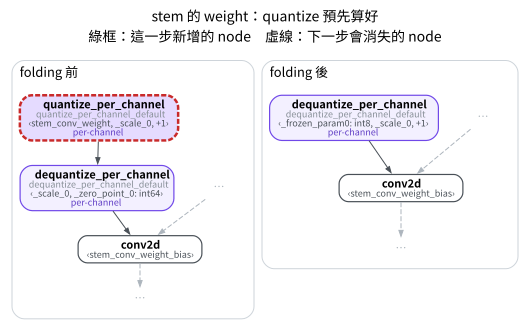

In [14]:
def get_attr_value(gm, target):
    obj = gm
    for part in target.split("."):
        obj = getattr(obj, part)
    return obj


def fold_weight_quantize(gm):
    """quantize_per_channel(get_attr weight) 的結果是常數：預先算好，存成 int8 buffer。"""
    graph = gm.graph
    folded = 0
    for node in list(graph.nodes):
        if node.op != "call_function" or node.target != QD.quantize_per_channel.default:
            continue
        if node.args[0].op != "get_attr":  # 只折 weight；activation 的輸入要到執行時才知道
            continue
        w, scale, zp = (get_attr_value(gm, a.target) for a in node.args[:3])
        w_int8 = QD.quantize_per_channel(w, scale, zp, *node.args[3:])  # 直接呼叫 op，算出 int8 weight
        name = f"_frozen_param{folded}"
        gm.register_buffer(name, w_int8)
        with graph.inserting_before(node):
            new = graph.get_attr(name)
        node.replace_all_uses_with(new)
        graph.erase_node(node)
        folded += 1
    graph.eliminate_dead_code()  # fp32 weight 的 get_attr 沒人用了，一併清掉
    graph.lint()
    gm.recompile()
    return folded


before = copy.deepcopy(manual)
n_fold = fold_weight_quantize(manual)
draw_stages([(before, "folding 前"), (manual, "folding 後")],
            focus=["quantize_per_channel_default", "dequantize_per_channel_default", "conv2d"], hops=0,
            title="stem 的 weight：quantize 預先算好")

左邊的 `quantize_per_channel` 吃 fp32 的 `stem_conv_weight`；右邊它消失了，dequantize 直接讀 int8 的 `_frozen_param0`。
圖上實際使用的 weight（`get_attr` 讀的、≥ 2 維的 tensor，bias 是 1 維不算）變小了：

In [15]:
def graph_weight_bytes(gm):
    total = 0
    for n in gm.graph.nodes:
        if n.op == "get_attr":
            t = get_attr_value(gm, n.target)
            if isinstance(t, torch.Tensor) and t.dim() >= 2:
                total += t.numel() * t.element_size()
    return total


table([["folding 前", f"{graph_weight_bytes(before):,}"],
       ["folding 後", f"{graph_weight_bytes(manual):,}"],
       ["convert_pt2e", f"{graph_weight_bytes(official):,}"]],
      ["圖", "weight 大小（bytes）"])

圖,weight 大小（bytes）
folding 前,"39,104"
folding 後,"9,776"
convert_pt2e,"9,776"


In [16]:
assert n_fold == 5
assert graph_weight_bytes(before) == 4 * graph_weight_bytes(manual) == 4 * graph_weight_bytes(official)

fp32 是 4 bytes、int8 是 1 byte，正好縮小 4 倍，與 `convert_pt2e` 相同。最後比一次 op 組成與輸出：

In [17]:
table(diff_ops(official, manual, "official", "manual", tablefmt="html"))

op,official,manual,delta
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
dequantize_per_channel,5,5,0
dequantize_per_tensor,12,12,0
flatten,1,1,0
linear,1,1,0
max_pool2d,2,2,0
quantize_per_tensor,11,11,0
relu,4,4,0


In [18]:
print(f"與 convert_pt2e 的輸出最大差 = {max_diff(official, manual):.3e}")
assert op_counts(official) == op_counts(manual) and max_diff(official, manual) == 0

與 convert_pt2e 的輸出最大差 = 0.000e+00


三個步驟做完，手寫的圖與 `convert_pt2e` 的 op 組成、輸出都完全相同。被略過的兩步（`_fold_conv_bn_qat`、`PortNodeMetaForQDQ`）在這張 PTQ 圖上不影響結果。

## 小結

- observer → q/dq 是把校準得到的 scale、zero point 寫死進圖：convert 之前它們存在 observer 模組裡，之後是圖上的常數或 buffer。
- convert 只透過 `calculate_qparams()` 讀 qparams（torchao `convert.py`），`FakeQuantize` 也有這個方法，所以 QAT 的圖走同一條路。
- weight 的 quantize 輸入是常數，可以預先算好、只存 int8；activation 的 q/dq 要等執行時才有輸入，必須留在圖上。
- 結果仍是 Q/DQ 圖：dequantize 後面接的還是 fp32 的 `conv2d`，不會變快。換成整數 kernel 是後端的事（M07～M09）。